# Comparing independently evolved luciferases

**Question:** do luciferases that evolved separately share any protein-sequence or physicochemical features?

This notebook re-runs the whole analysis from the curated dataset (51 luciferases in 7 families, plus 7 non-luminous controls) and shows the key results. Plain-language explanations are in `docs/PROJECT_REPORT.md`.

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 160)

## 1. Dataset check (W3: biological databases)
The curated FASTA files and manifest are checked against `data/seeds.csv` (offline).

In [2]:
import subprocess
print(subprocess.run([sys.executable, '-m', 'src.verify_data'], capture_output=True, text=True).stdout)

note: no InterPro/Pfam annotation for 15: XRP75328.1 BCK50966.1 Q9BLZ2 Q6UQE3 I7GGY2 H3JS09 U3TKG7 H3JS11 U3TIM6 H3JS17 H3JS19 H3JS13 BAD08210.1 QOS14273.1 XRP75329.1
firefly         {'luciferase': 8, 'control': 2}
renilla_type    {'luciferase': 3, 'control': 3}
bacterial_luxa  {'luciferase': 10, 'control': 1}
fungal_luz      {'luciferase': 9, 'control': 1}
copepod         {'luciferase': 10}
dinoflagellate  {'luciferase': 8}
ostracod        {'luciferase': 3}
ISSUES none
DATASET VERIFIED



## 2. Protein properties (W14: proteomics)
Biopython ProtParam: length, molecular weight, pI, GRAVY, aromaticity, amino-acid composition.

In [3]:
from src import features
features.run()
pd.read_csv('results/features_by_family.csv')

wrote 58 proteins to results/features.csv


,family,role,n,length_median,length_min,length_max,molecular_weight_kda_median,molecular_weight_kda_min,molecular_weight_kda_max,isoelectric_point_median,isoelectric_point_min,isoelectric_point_max,gravy_median,gravy_min,gravy_max,aromaticity_median,aromaticity_min,aromaticity_max
0,firefly,luciferase,8,547.5,545,550,60.471,60.017,60.744,6.450,5.903,8.395,-0.080,-0.110,-0.040,0.093,0.082,0.101
1,firefly,control,2,544.0,544,544,59.958,59.938,59.977,8.422,8.255,8.588,-0.016,-0.028,-0.004,0.081,0.079,0.083
2,renilla_type,luciferase,3,311.0,311,322,36.113,36.022,37.549,5.860,5.670,5.978,-0.430,-0.535,-0.422,0.119,0.119,0.127
3,renilla_type,control,3,296.0,293,314,33.246,33.107,36.226,5.029,4.949,5.907,-0.228,-0.531,-0.137,0.109,0.098,0.118
4,bacterial_luxa,luciferase,10,354.5,346,362,40.356,39.364,41.401,5.384,4.949,5.748,-0.378,-0.444,-0.319,0.104,0.099,0.122
5,bacterial_luxa,control,1,381.0,381,381,41.736,41.736,41.736,5.694,5.694,5.694,-0.192,-0.192,-0.192,0.079,0.079,0.079
6,fungal_luz,luciferase,9,261.0,246,267,29.700,27.396,30.381,8.633,6.513,9.376,-0.236,-0.327,-0.180,0.086,0.080,0.093
7,fungal_luz,control,1,283.0,283,283,31.416,31.416,31.416,8.159,8.159,8.159,-0.172,-0.172,-0.172,0.092,0.092,0.092
8,copepod,luciferase,10,210.5,185,223,22.981,19.900,24.322,7.076,5.179,9.117,-0.101,-0.343,0.095,0.053,0.047,0.064
9,dinoflagellate,luciferase,8,1237.0,914,1242,136.901,102.187,137.286,6.162,5.763,7.497,-0.491,-0.563,-0.290,0.101,0.084,0.103


## 3. Pairwise alignment (W6–W8: similarity, global and local alignment)
Needleman–Wunsch identity for all 1,653 pairs, plus Smith–Waterman z-scores against shuffled sequences (z near 0 = chance). Takes about 2–3 minutes.

                           global_identity_pct_count  global_identity_pct_median  global_identity_pct_min  global_identity_pct_max  local_zscore_count  local_zscore_median  local_zscore_min  local_zscore_max
category                                                                                                                                                                                                       
control vs control                                 4                   45.322436                42.662116                49.146758                   4            71.241294         42.460648         86.788878
cross-family                                    1087                   19.905213                 0.182482                30.731707                1087            -0.060566         -3.081257          5.349969
cross-family (control)                           330                   18.283112                 1.606426                27.225131                 330            -0.132

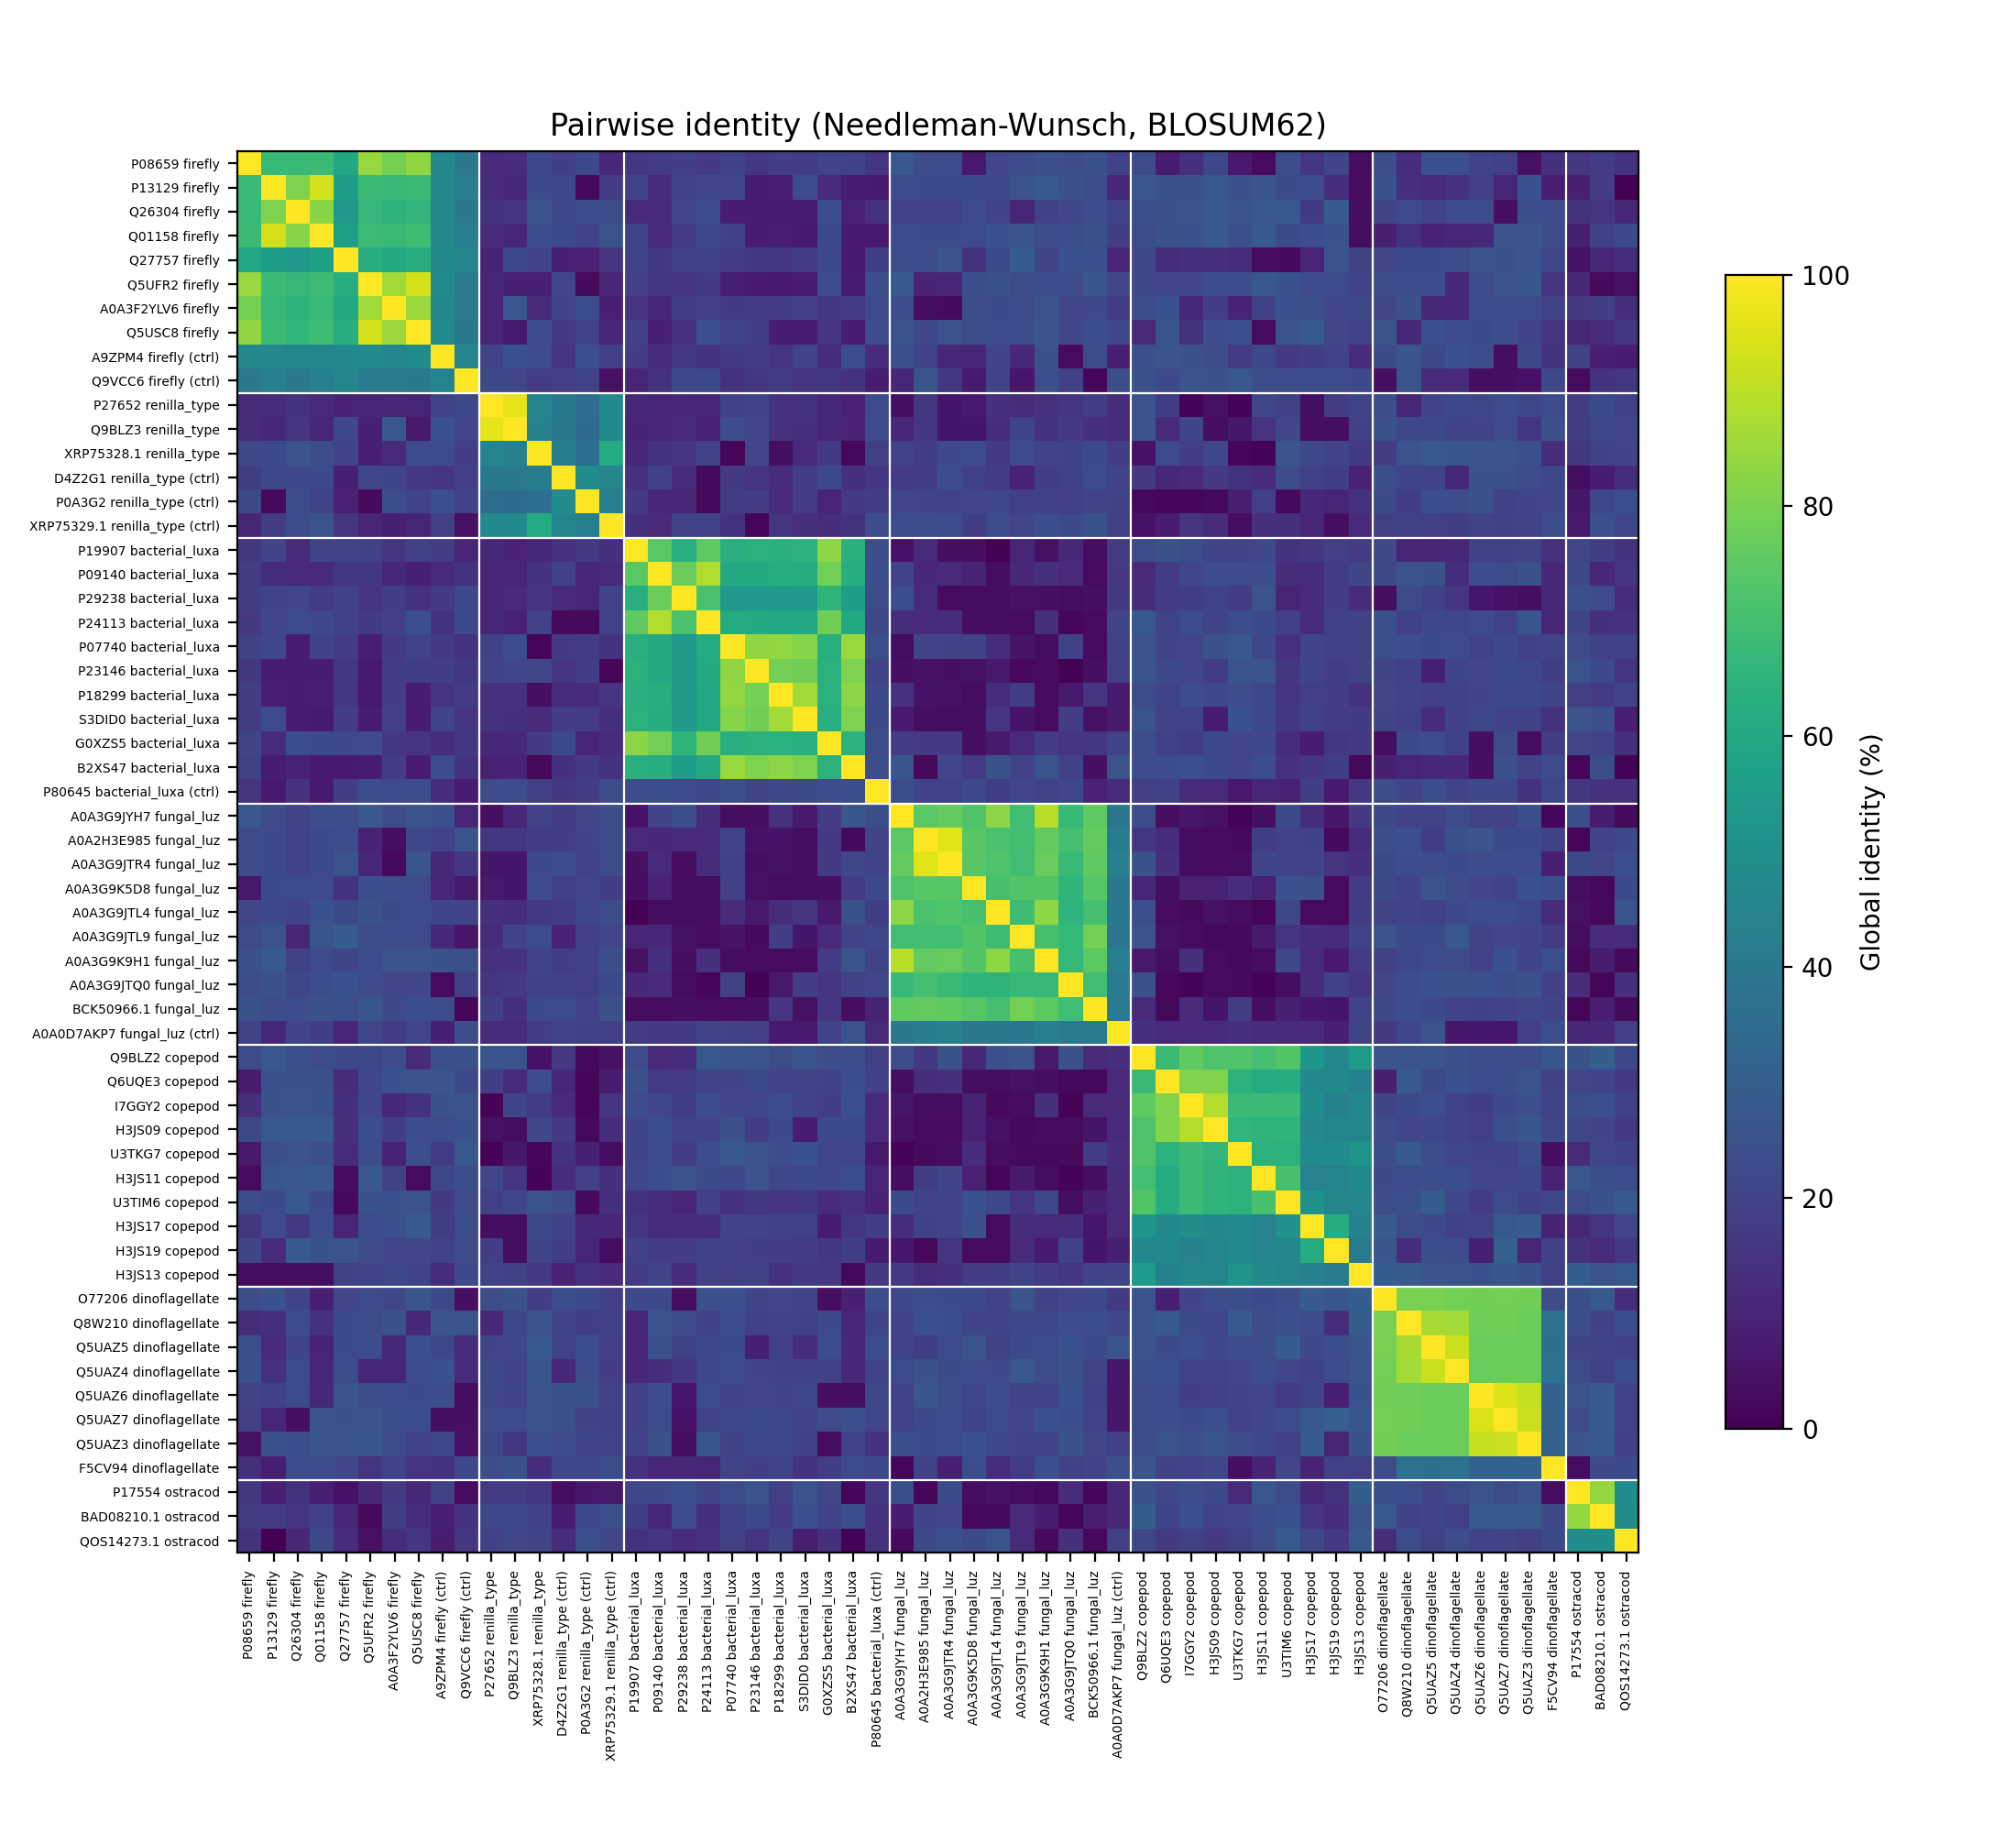

In [4]:
from src import align
align.run()
display(Image('results/figures/identity_heatmap.png', width=750))

In [5]:
print(open('results/example_alignments.txt').read()[:3000])

=== Global (Needleman-Wunsch): P08659 (firefly) vs P13129 (firefly) | score 1949.5 ===
target            0 ---MEDAKNIKKGPAPFYPLEDGTAGEQLHKAMKRYALVPGTIAFTDAHIEVNITYAEYF
                  0 ---||...||..||.||||.|.|.||.||.|.|.|||..-|.||||.|...|...||||.
query             0 MENMENDENIVVGPKPFYPIEEGSAGTQLRKYMERYAKL-GAIAFTNAVTGVDYSYAEYL

target           57 EMSVRLAEAMKRYGLNTNHRIVVCSENSLQFFMPVLGALFIGVAVAPANDIYNERELLNS
                 60 |.|..|..|...|||....||..||||...||.||...|||||.|||.|.||..|||..|
query            59 EKSCCLGKALQNYGLVVDGRIALCSENCEEFFIPVIAGLFIGVGVAPTNEIYTLRELVHS

target          117 MNISQPTVVFVSKKGLQKILNVQKKLPIIQKIIIMDSKTDYQGFQSMYTFVTSHLPPGFN
                120 ..||.||.||.|||||.|...|||....|..|.|.|||.||.|.|...||.....||||.
query           119 LGISKPTIVFSSKKGLDKVITVQKTVTTIKTIVILDSKVDYRGYQCLDTFIKRNTPPGFQ

target          177 EYDFVPESFDRDKTIALIMNSSGSTGLPKGVALPHRTACVRFSHARDPIFGNQIIPDTAI
                180 ...|.....||....||||||||||||||||.|.|.....|||||||||.|||..|.||.
query           179

## 4. Dot plots (W9)

P08659 vs P13129: 479 dots


P08659 vs A9ZPM4: 334 dots
P08659 vs P19907: 6 dots


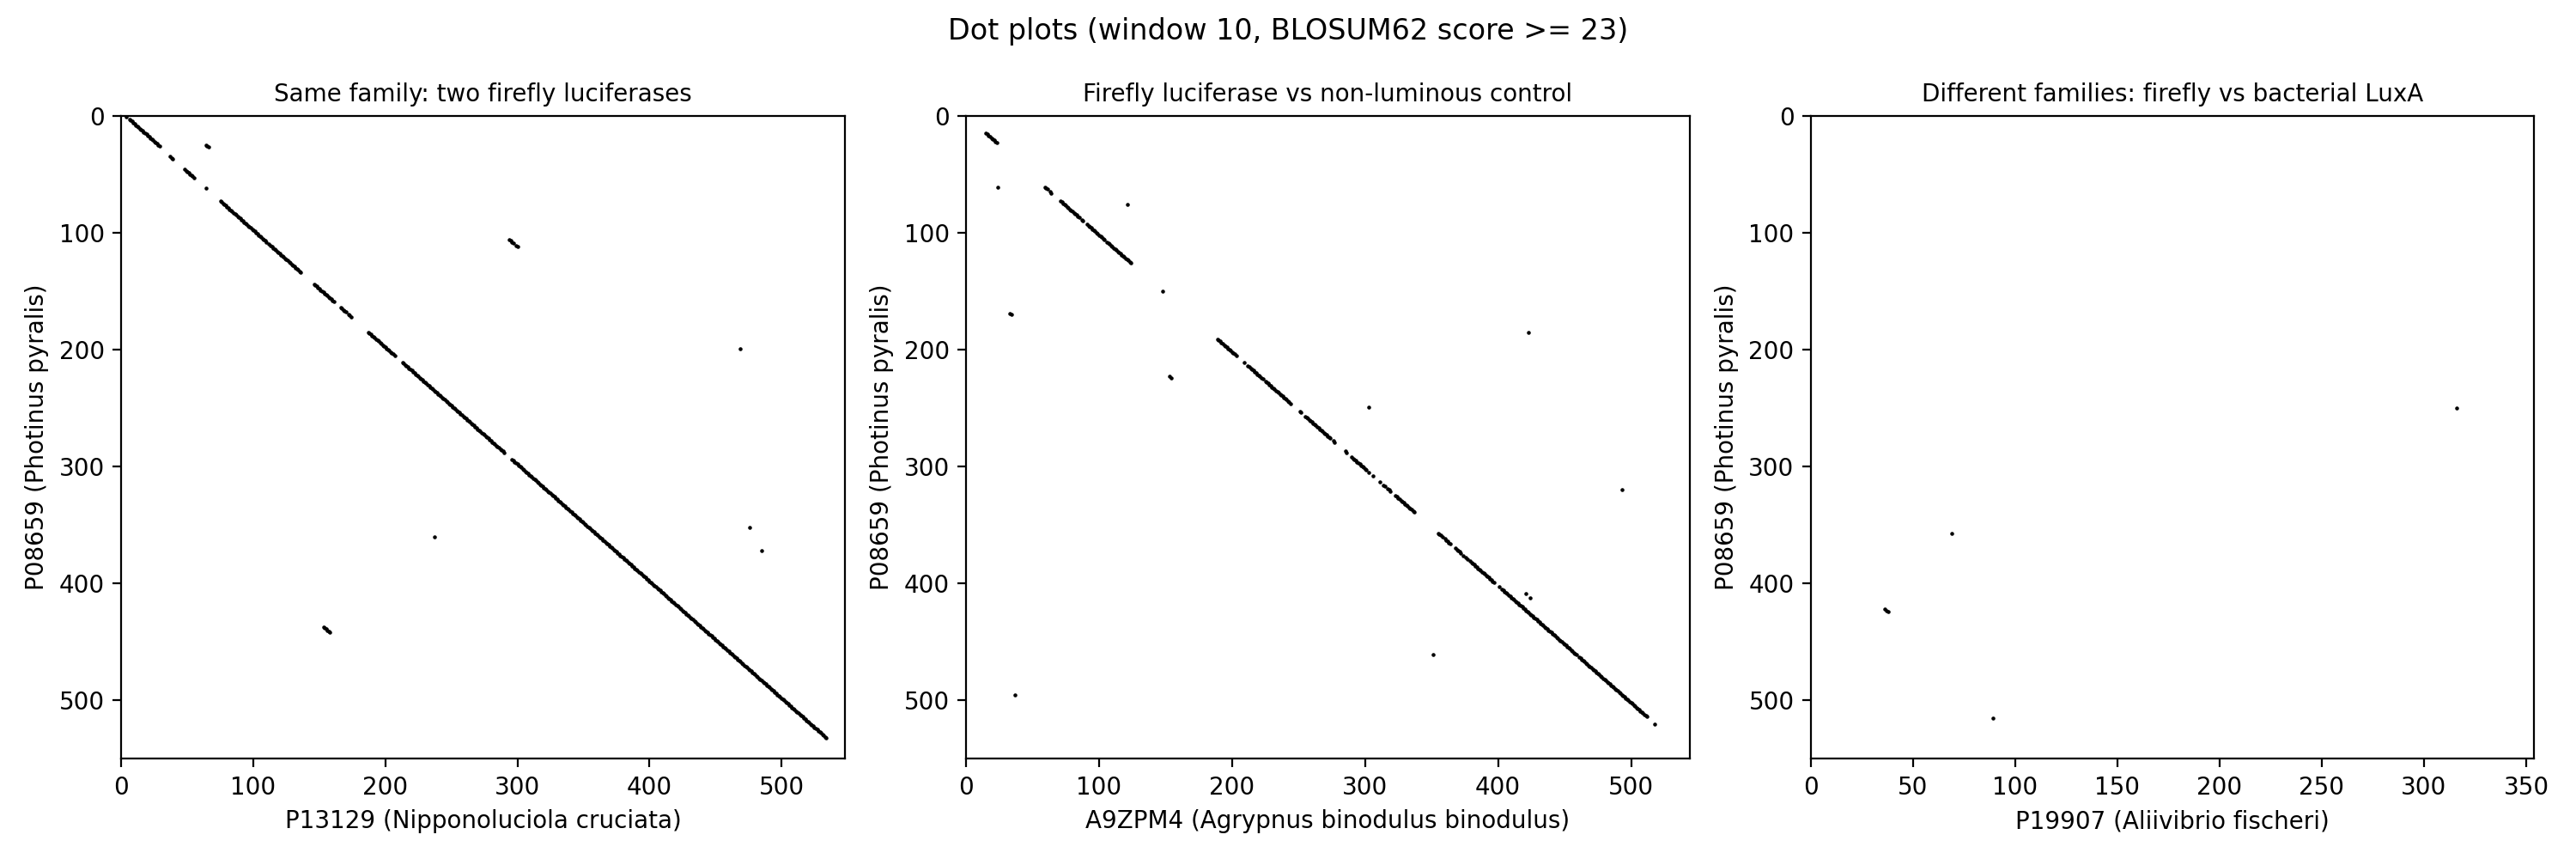

In [6]:
from src import dotplot
dotplot.run()
display(Image('results/figures/dotplots.png', width=900))

## 5. BLAST (W12)
Local BLAST+ all-vs-all at E < 0.001.

In [7]:
from src import blast
blast.run()

458 hits at E < 0.001; 0 of 58 queries hit another family
                           same_family_hits  cross_family_hits
family         role                                           
firefly        luciferase                72                  0
renilla_type   luciferase                15                  0
bacterial_luxa luciferase                93                  0
fungal_luz     luciferase                81                  0
copepod        luciferase                90                  0
dinoflagellate luciferase                56                  0
ostracod       luciferase                 6                  0
firefly        control                   18                  0
renilla_type   control                   15                  0
bacterial_luxa control                    3                  0
fungal_luz     control                    9                  0


,accession,family,role,same_family_hits,cross_family_hits,cross_family_subjects,best_cross_family_evalue
0,P08659,firefly,luciferase,9,0,,None
1,P13129,firefly,luciferase,9,0,,None
2,Q26304,firefly,luciferase,9,0,,None
3,Q01158,firefly,luciferase,9,0,,None
4,Q27757,firefly,luciferase,9,0,,None
5,Q5UFR2,firefly,luciferase,9,0,,None
6,A0A3F2YLV6,firefly,luciferase,9,0,,None
7,Q5USC8,firefly,luciferase,9,0,,None
8,P27652,renilla_type,luciferase,5,0,,None
9,Q9BLZ3,renilla_type,luciferase,5,0,,None


## 6. Within-family trees (W10)
Neighbour-joining from Poisson distances. No tree mixes families: unrelated proteins cannot be meaningfully aligned together.

firefly: 10 sequences
renilla_type: 6 sequences
bacterial_luxa: 11 sequences
fungal_luz: 10 sequences
copepod: 10 sequences
dinoflagellate: 8 sequences
ostracod: 3 sequences


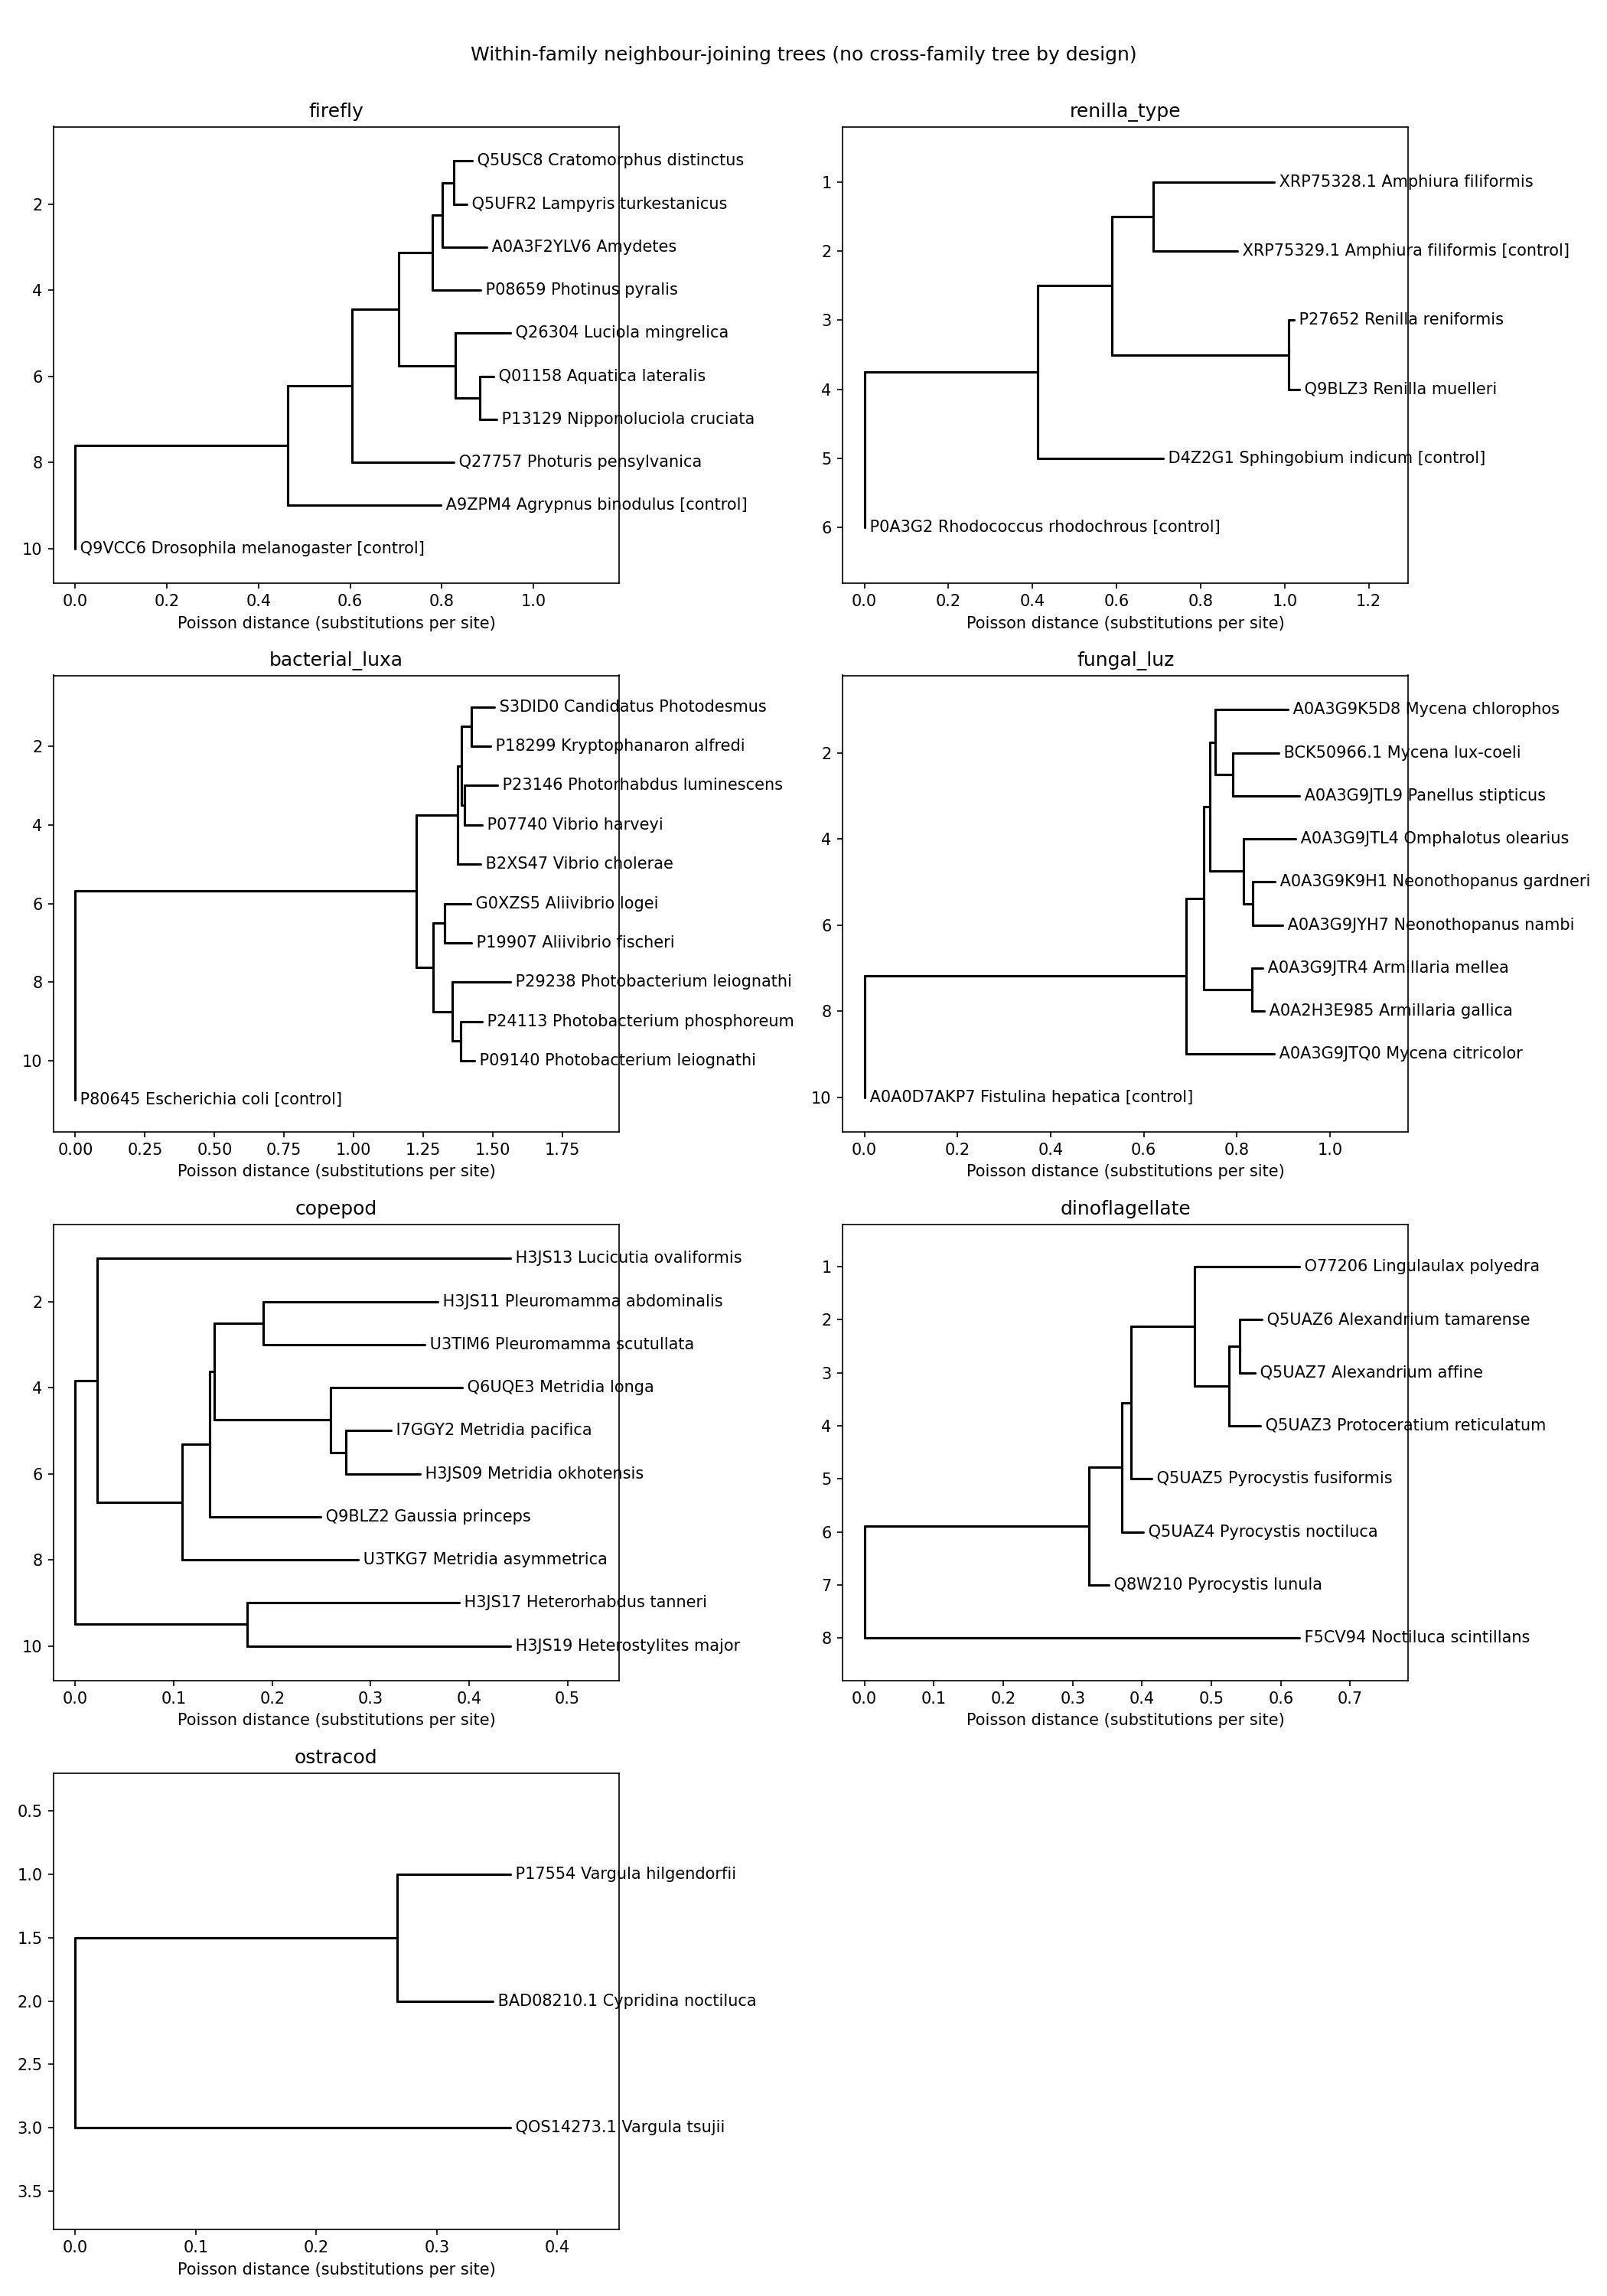

In [8]:
from src import phylo
phylo.run()
display(Image('results/figures/trees.png', width=800))

## 7. Clustering and statistics (W11)
Do luciferases group by family, or by "makes light"? Do luciferases differ from their own controls in a consistent direction?

                                             test           feature  statistic      p_value  n
  Ward clustering vs family (adjusted Rand index)   all composition   0.968528          NaN 51
      Kruskal-Wallis across 7 luciferase families             gravy  41.892132 1.931183e-07 51
      Kruskal-Wallis across 7 luciferase families isoelectric_point  35.139681 4.049107e-06 51
      Kruskal-Wallis across 7 luciferase families       aromaticity  41.579324 2.226124e-07 51
      Kruskal-Wallis across 7 luciferase families          aa_C_pct  45.037355 4.600901e-08 51
Sign test: luciferase vs own control (4 families)             gravy   0.000000 1.250000e-01  4
Sign test: luciferase vs own control (4 families) isoelectric_point   2.000000 1.000000e+00  4
Sign test: luciferase vs own control (4 families)       aromaticity   3.000000 6.250000e-01  4
Sign test: luciferase vs own control (4 families)          aa_C_pct   2.000000 1.000000e+00  4
family            bacterial_luxa firefly fungal_lu

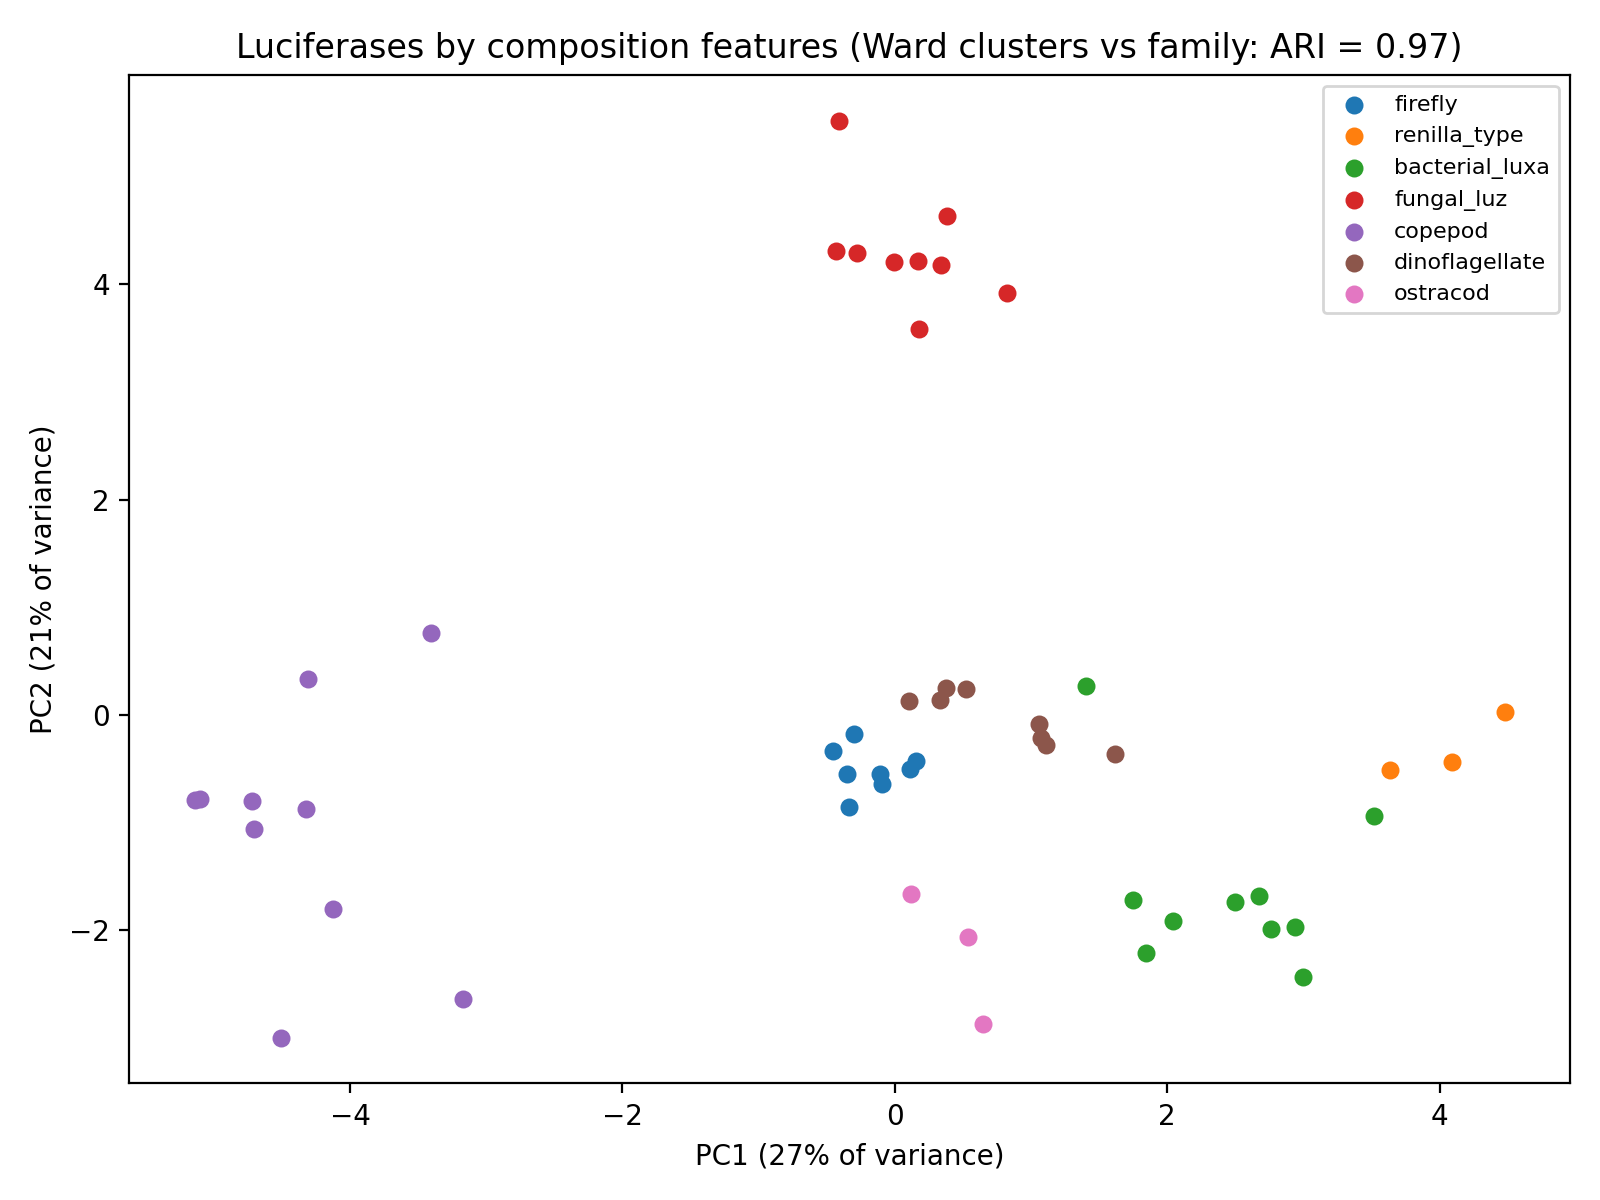

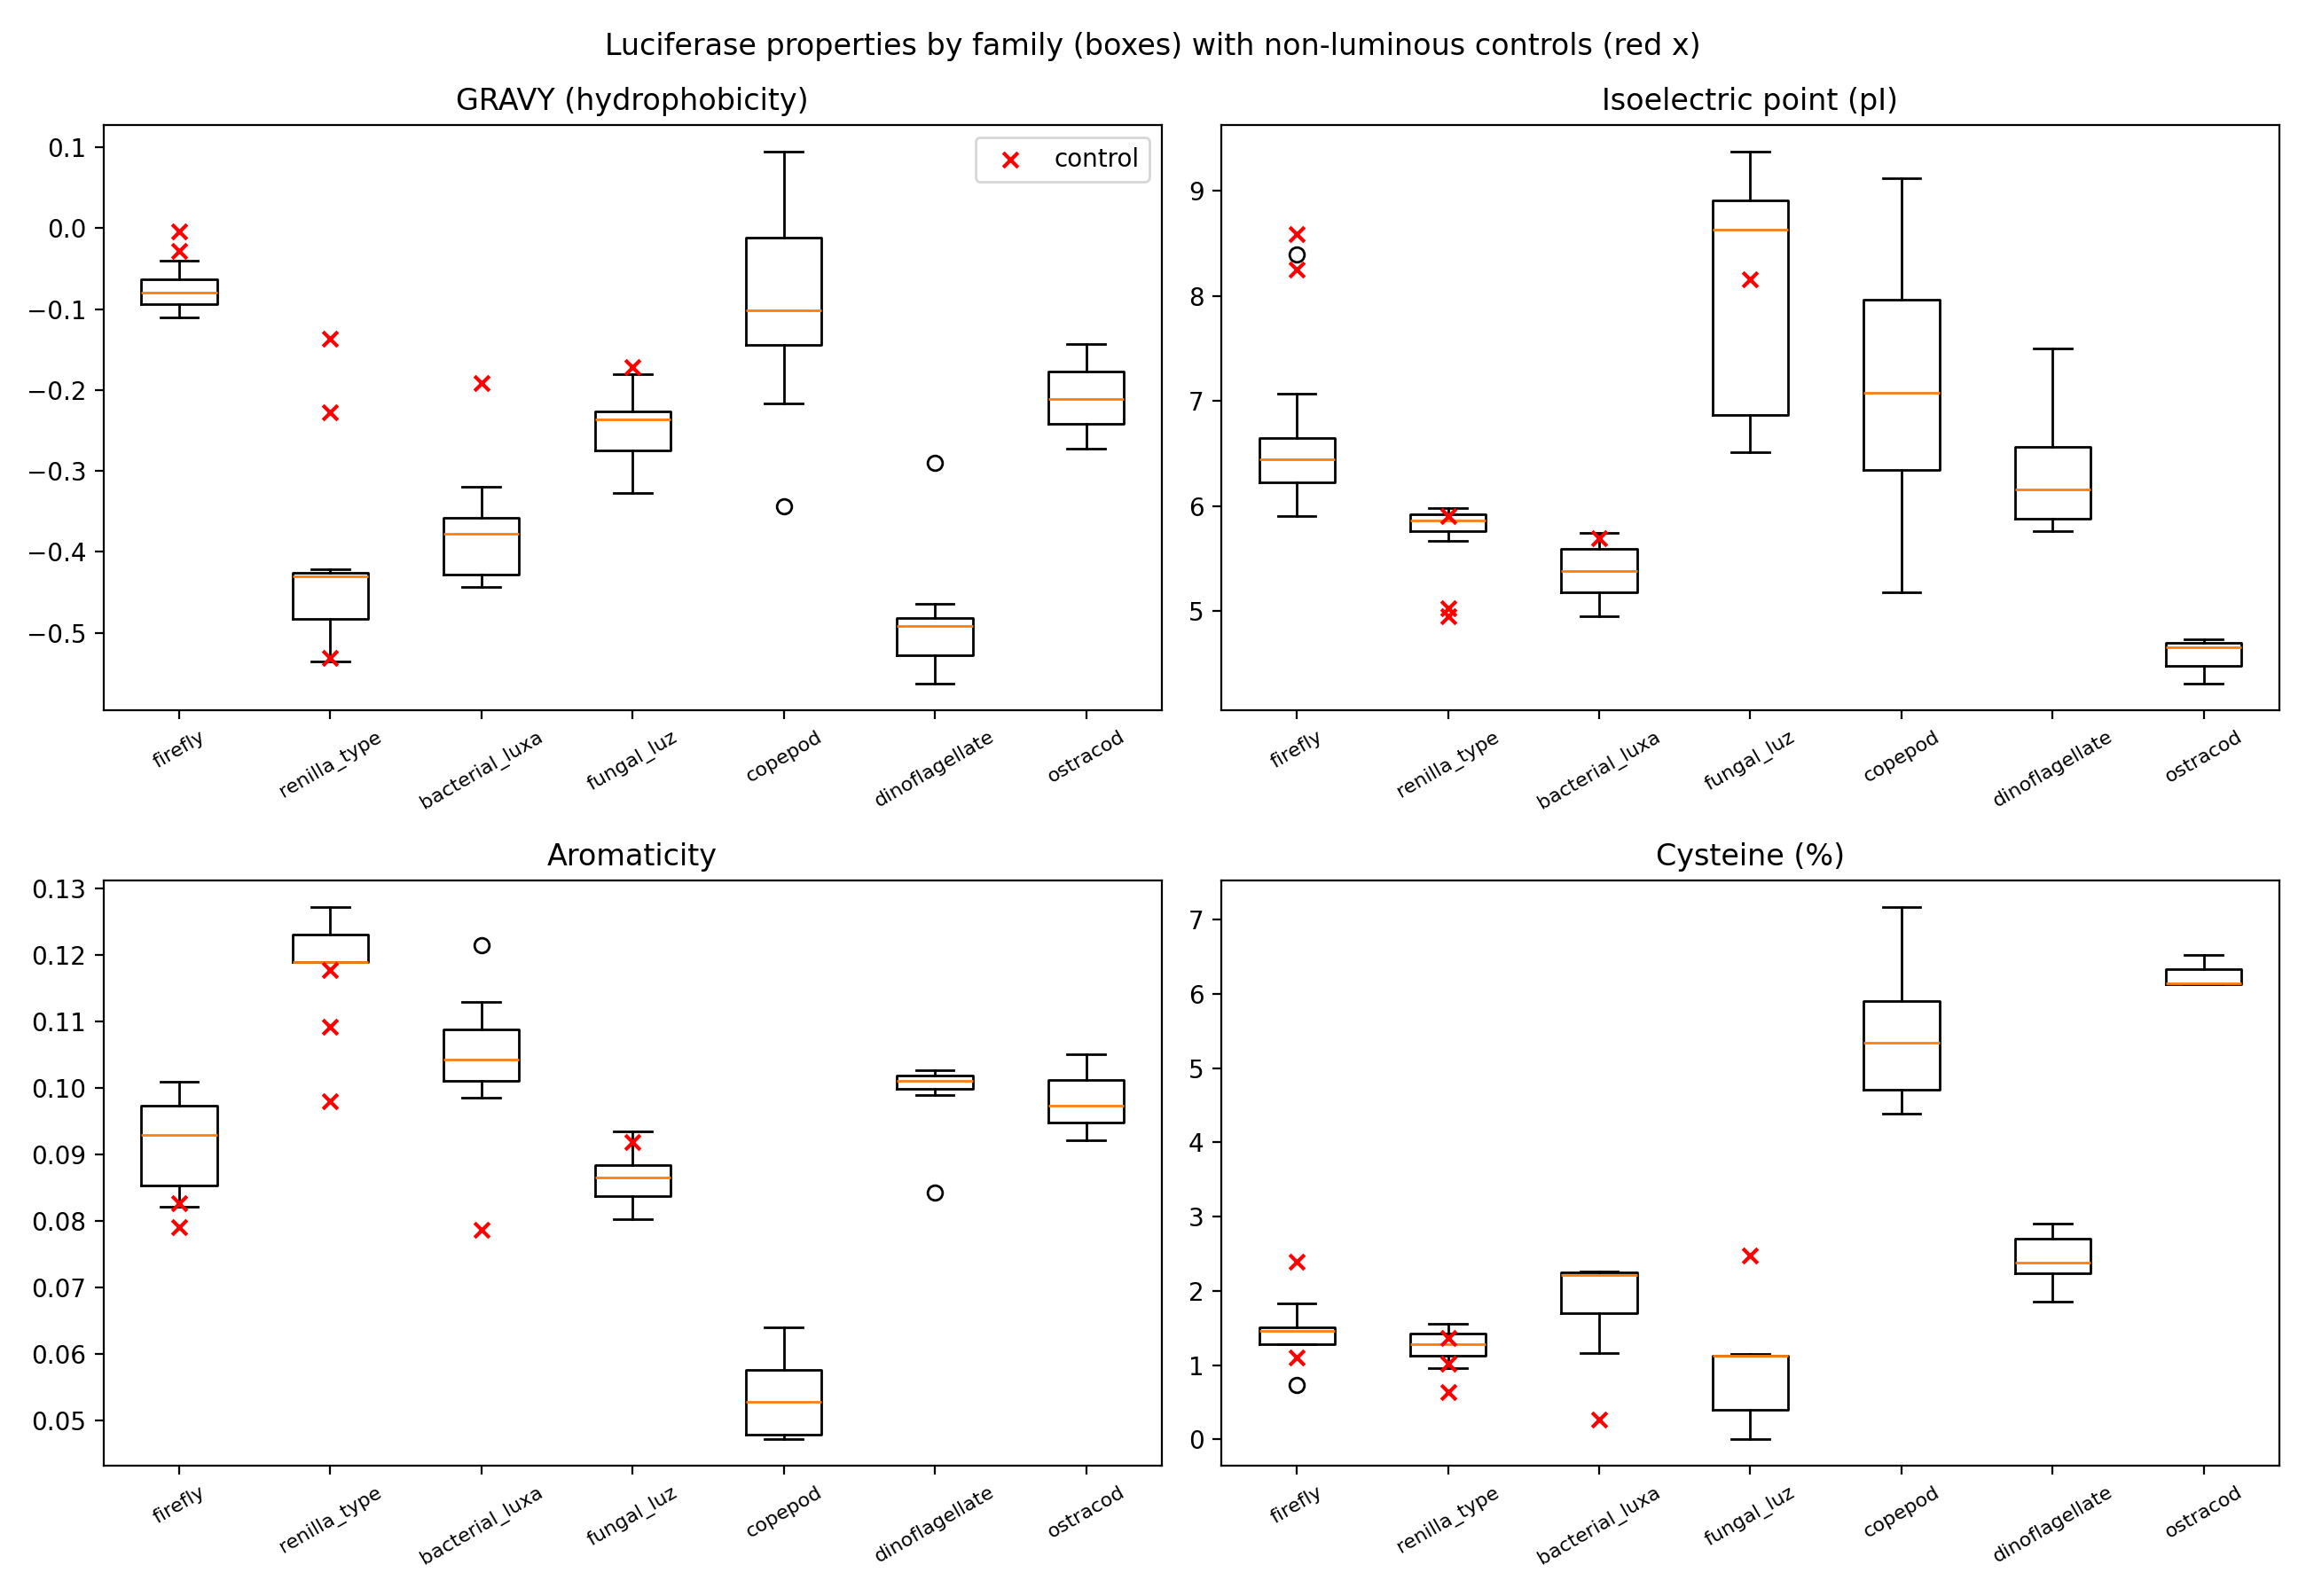

In [9]:
from src import analysis
analysis.run()
display(Image('results/figures/pca_features.png', width=650))
display(Image('results/figures/feature_boxplots.png', width=850))

In [10]:
pd.read_csv('results/control_comparison.csv')

,family,feature,luciferase_median,control_median,difference,direction
0,firefly,gravy,-0.0795,-0.0159,-0.0636,lower
1,firefly,isoelectric_point,6.4495,8.4216,-1.9721,lower
2,firefly,aromaticity,0.0930,0.0809,0.0121,higher
3,firefly,aa_C_pct,1.4599,1.7463,-0.2864,lower
4,renilla_type,gravy,-0.4299,-0.2280,-0.2019,lower
5,renilla_type,isoelectric_point,5.8602,5.0291,0.8311,higher
6,renilla_type,aromaticity,0.1190,0.1092,0.0098,higher
7,renilla_type,aa_C_pct,1.2862,1.0135,0.2727,higher
8,bacterial_luxa,gravy,-0.3781,-0.1916,-0.1865,lower
9,bacterial_luxa,isoelectric_point,5.3839,5.6939,-0.3100,lower


## 8. Conclusion

- Luciferases are clearly related **within** a family and show no detectable sequence similarity **across** families (cross-family identity ≈ 20%, chance-level z-scores, no BLAST hits).
- Composition separates proteins by **family** almost perfectly: inheritance, not light production, dominates their properties.
- No property shifts in a consistent, significant direction between luciferases and their non-luminous controls. Lower hydrophobicity in 4 of 4 families is suggestive only (sign test p = 0.125).
- **Answer:** at the protein level, independently evolved luciferases do not share a detectable common signature; they converged in function, not in sequence or overall properties.